In [1]:
from sklearn.cluster import KMeans
import numpy as np
import matplotlib.pyplot as plt

import numpy as np
import joblib
import importlib
import matplotlib.pyplot as plt
import os 
import pickle
import bayes_logistic as bl
from collections import defaultdict
import warnings
warnings.filterwarnings("ignore")
from tqdm import trange, tqdm
import math

os.chdir('/Users/eochoa/Documents/Research_Ambuj/ASD/Code/')

import pandas as pd
from utils import *
#from linear_utils import *
from logistic_utils import *
from GP_utils import *
from linear_utils import *
import expt_utils as expt_utils
from sklearn.preprocessing import normalize
from sklearn.datasets import load_iris
from sklearn.gaussian_process import GaussianProcessClassifier
from sklearn.gaussian_process import GaussianProcessRegressor
from sklearn.mixture import GaussianMixture
from sklearn.mixture import BayesianGaussianMixture
from sklearn.linear_model import LogisticRegression
from scipy.special import expit, logit
import sklearn
import seaborn as sns
# importlib.reload(expt_utils)
from sklearn.neighbors import NearestNeighbors

from sklearn.metrics import pairwise_distances

from scipy.stats import multivariate_normal

In [2]:
pd.read_csv('/Users/eochoa/Downloads/MEC_02_063_FHS_back_Al_slide_03292023_04262023_run2_test1.csv')

,0,0.1,0.2,0.3,0.4,0.5,0.6,0.7,0.8,0.9,...,0.502,0.503,0.504,0.505,0.506,0.507,0.508,0.509,0.510,0.511
0,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
1,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
2,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
3,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
4,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
378,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
379,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
380,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
381,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0


In [3]:
expit = lambda x: 1/(1+np.exp(-x))
def gen_data(N=100, p=2, scale=1):

    #N = 10000
    #p = 10
    theta = scale*(2*np.random.rand(p)-1)
    r = np.random.rand(N).reshape(N, 1)-1
    x = np.random.rand(N,p).reshape(N, p)
    x = x - x.mean(0)
    x = r*normalize(x, axis=1, norm='l2')
    
    #x = np.random.rand(p*N).reshape(N, p)
    
    x_ = np.concatenate([np.ones((N,1)), x],axis=1)
    f = x @ theta
    #f = np.power(f,2)
    p = expit(f)
    y = np.random.binomial(1,p)
    return x, y, theta

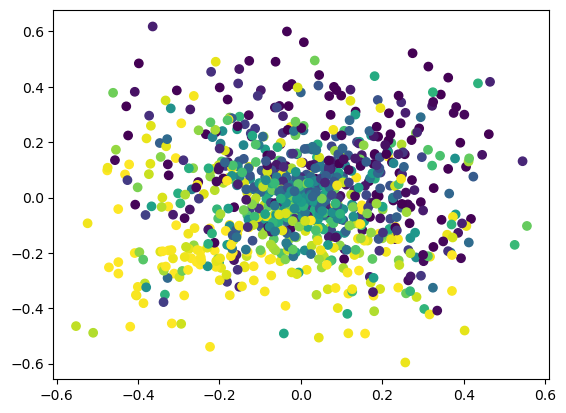

In [4]:
x, y, theta = gen_data(1000, p=10, scale=10)
plt.scatter(x[:,0],x[:,1], c=expit(x @ theta))

In [5]:
clf = LogisticRegression(random_state=0, C=10)

In [6]:
#x_ = (x - x.mean(0)) / (x.std(0))
x_, _, _ = gen_data(1000, p=10, scale=10)
f = x_ @ theta
p = expit(f)
y_ = np.random.binomial(1,p)
    
clf.fit(x, y)
clf.score(x_, y_)

0.783

In [7]:
clf.decision_function

<bound method LinearClassifierMixin.decision_function of LogisticRegression(C=10, random_state=0)>

In [21]:
algos_dict = {
    'Greedy_logistic_freq': [Greedy_logistic_freq, {}, 10, 'Greedy_logistic_freq', 'y'],
    'Greedy_logistic': [G_logistic, {'prob_threshold':.35}, 10, 'Greedy_logistic', 'green'],
    'TS_logistic': [TS_logistic, {'prob_threshold':.25}, 10, 'TS_logistic', 'red'],
    #'Greedy_logistic_2': [G_logistic, {'n_clus':50, 'ss_size':5, 'optimal_marg':.5}, 1, 'Greedy_logistic_2', 'green']
}

In [22]:
#res_G = defaultdict(list)

act_list = {algo:[] for algo in algos_dict}
reg_list = {algo:[] for algo in algos_dict}
rwd_ev_list = {algo:[] for algo in algos_dict}
rwd_list = {algo:[] for algo in algos_dict}
rwd_prop_list = {algo:[] for algo in algos_dict}
tau_list = {algo:[] for algo in algos_dict}
tau_true_list = {algo:[] for algo in algos_dict}
sample_list = {var:[] for var in ['x', 'y', 'theta', 'true_tau']}

for trial_idx in trange(10):
    x, y, theta = gen_data(100, scale=10)
    n_row, n_col = y.shape[0], 1
    _, n_desc =  x.shape
    cutoff = n_desc
    T = n_row
    prob_dict = {
                "m": n_row,
                "noise": 0.01,
                "d": cutoff
              }
    prob = logistic_discover(**prob_dict)
    #x = x - x.mean(0)
    #x = normalize(x, axis=0, norm='l2')
    prob.x = x.copy()
    prob.y = y.copy()
    #t_prob = deepcopy(prob)
    #solver = G_logistic(t_prob, prob_threshold=0.25) 
        #reg, act = solver.run(T, refresh=False)[:2]

        #actions_0 = [np.random.choice(np.arange(1000)[kmeans.labels_ == c]) for c in range(10)]

    #reg, rwd, tau = solver.run(T)
    
    #res_G['true_tau'].append(((y[np.argsort(expit(x @ theta))[::-1]].cumsum()/y.sum() > 0.95).cumsum() == 0).sum())
    #res_G['reg'].append(reg)
    #res_G['tau'].append(tau)
    #res_G['rwd_prop'].append(np.array(rwd).sum()/y.sum())
    
    sample_list['x'].append(x)
    sample_list['y'].append(y)
    sample_list['true_tau'].append(((y[np.argsort(expit(x @ theta))[::-1]].cumsum()/y.sum() > 0.95).cumsum() == 0).sum())
    
    sample_list['theta'].append(theta)
    
    for algo, algo_setup in algos_dict.items():
        t_prob = deepcopy(prob)
        algo_func, algo_params, algo_N_trials, _, _ = algo_setup
                        # print(algo_func)
        if not trial_idx < algo_N_trials:
            continue
        solver = algo_func(t_prob, **algo_params)
        reg, rwd, tau = solver.run(T)#[:2]
                #act_list[algo].append(getattr(solver, "logistic_discover"))
                #act_list[algo].append(t_prob.actions)
                # print(prob.rewards)
        if np.isnan(tau):
            tau = T
        act_list[algo].append(t_prob.actions)
        reg_list[algo].append(reg)
        rwd_list[algo].append(rwd)
        rwd_ev_list[algo].append(t_prob.rewards_ev)
        tau_true_list[algo].append(t_prob.tau_true)
        tau_list[algo].append(tau)
        rwd_prop_list[algo].append(np.array(rwd)[:tau].sum()/y.sum())
        

100%|███████████████████████████████████████████| 10/10 [00:05<00:00,  1.73it/s]


In [23]:
#np.max([np.linalg.norm(x_) for x_ in x])
np.linalg.eigvals(x.T @ x)

array([16.6832316 , 13.75165913])

In [24]:
f = x @ theta
p = expit(f)
c_mu = (expit(f) * (1 - expit(f))).min()

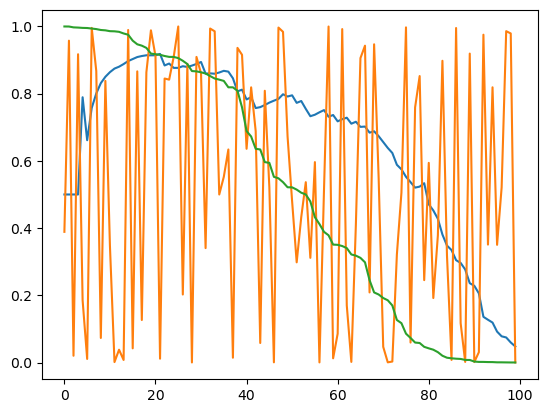

In [25]:
plt.plot(rwd_ev_list['Greedy_logistic_freq'][0])
plt.plot(p[act_list['Greedy_logistic_freq'][0]])
plt.plot(np.sort(p)[::-1])

In [26]:
times_list = np.arange(1,101)
delta = 0.2
d = 2
kappa = np.sqrt(3+2*np.log(1+2/13.38708758))
kappa

1.8106562677254208

In [27]:
np.array([x[act_list['Greedy_logistic_freq'][0]][i] @ np.linalg.inv(x[act_list['Greedy_logistic_freq'][0]][:max(2,i)].T @ x[act_list['Greedy_logistic_freq'][0]][:max(2,i)]) @ x[act_list['Greedy_logistic_freq'][0]][i] for i in range(100)])



array([1.00000000e+00, 1.00000000e+00, 2.46679517e+02, 1.56203988e+00,
       6.67372747e-01, 8.67936574e-01, 5.48757198e-01, 7.69303052e-02,
       7.78553179e-02, 3.18385209e-02, 1.24157354e-02, 4.45237625e-01,
       9.37903097e-02, 1.85691353e-01, 1.43811327e-01, 2.07189635e-01,
       3.01661886e-02, 5.86497936e-02, 1.98422340e-02, 3.80121801e-01,
       9.10284025e-02, 1.07503923e-01, 1.31712419e-02, 7.80088931e-02,
       2.89041898e-02, 2.75660233e-01, 2.25888607e-01, 1.23655663e-01,
       1.94509154e-01, 5.91183499e-02, 8.45572766e-03, 5.50966388e-02,
       7.28147295e-02, 5.66555764e-02, 4.70076470e-06, 4.63949202e-03,
       8.57504897e-04, 4.04157961e-02, 1.53986120e-02, 3.68482790e-02,
       1.27685242e-02, 4.08215421e-02, 1.51181726e-03, 1.53440124e-01,
       4.54950363e-03, 2.32586216e-04, 1.21463712e-01, 7.36666812e-02,
       4.38833035e-02, 3.89668909e-02, 2.15538824e-04, 6.97329553e-03,
       4.29245297e-03, 3.14600038e-02, 8.33014963e-03, 2.64574570e-04,
      

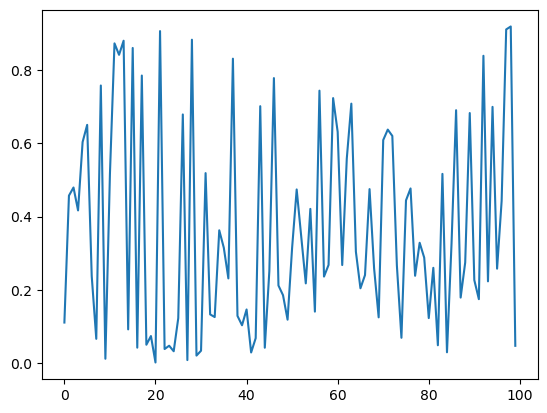

In [28]:
plt.plot(np.abs(rwd_ev_list['Greedy_logistic_freq'][0]-p[act_list['Greedy_logistic_freq'][0]]))
#np.sqrt(2*d*np.log(times_list) * np.log(2*d*times_list/delta))*2*1/4*kappa/c_mu
#plt.plot(np.array([x[act_list['Greedy_logistic_freq'][0]][i] @ np.linalg.inv(x[act_list['Greedy_logistic_freq'][0]][:max(2,i)].T @ x[act_list['Greedy_logistic_freq'][0]][:max(2,i)]) @ x[act_list['Greedy_logistic_freq'][0]][i] for i in range(100)]) * np.log(times_list) / (2*c_mu))                      



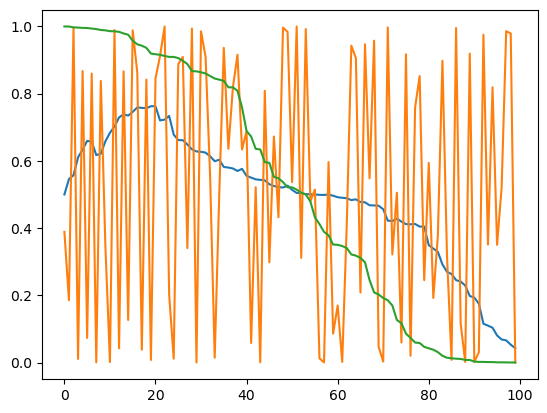

In [29]:
plt.plot(rwd_ev_list['Greedy_logistic'][0])
plt.plot(p[act_list['Greedy_logistic'][0]])
plt.plot(np.sort(p)[::-1])

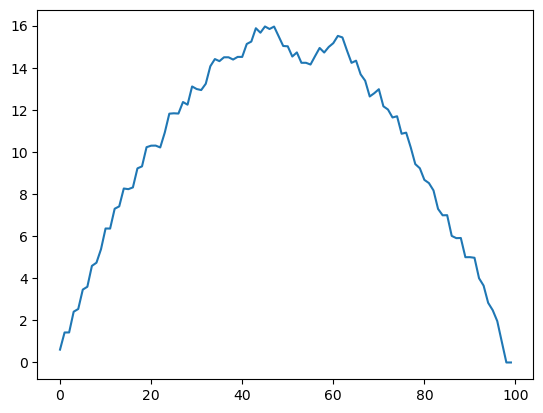

In [30]:
plt.plot(np.cumsum(np.sort(p)[::-1] - p[act_list['Greedy_logistic'][0]]))

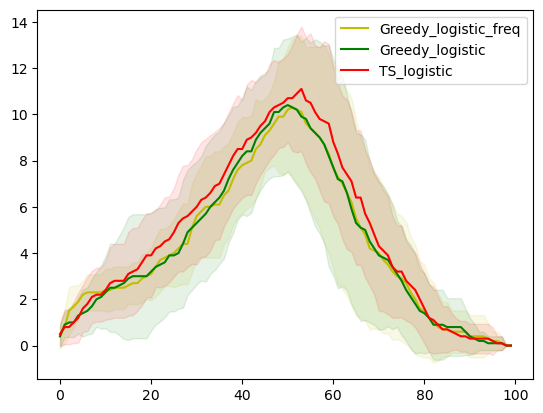

In [31]:
alpha = 0
for algo in algos_dict:
    algo_label = algos_dict[algo][3]
    algo_style = algos_dict[algo][4]
    y_ = np.mean(reg_list[algo], axis = 0)[:1000]
    y_ = y_ / np.power((np.ones(y_.shape[0])).cumsum(), alpha)
    ci = np.std(reg_list[algo], axis = 0)[:1000]/ np.power((np.ones(y_.shape[0])).cumsum(), alpha)
    plt.plot(range(y_.shape[0]), y_,
                  algo_style, label=algo_label)
    plt.fill_between(range(y_.shape[0]), (y_-ci), (y_+ci), color = algo_style, alpha=.1)

    plt.legend()